# VthCa parameter optimization to match experimental hysteresis

This notebook optimizes calcium channel activation thresholds (VthCa) for each motoneuron to match experimentally measured hysteresis profiles.

**Optimization method:**
- Black-box optimization (adaptive differential evolution)
- Individual optimization for each motoneuron
- Iterative refinement until convergence criterion met

---

## 1. Environment setup

### 1.1 Package imports

In [1]:
# Core packages
using Distributions, Random
using Parameters, Match, SymDict

# Optimization
using BlackBoxOptim
using Optim, JuMP, Ipopt

# Data handling
using JLD2, MAT, CSV, DataFrames, Serialization

# Numerical methods
using DSP, NumericalIntegration, Polynomials, GLM

# Visualization
using Plots, CairoMakie, Makie, PyPlot
using Colors, ColorSchemes

# Logging
using Wandb, Logging, PyCall

println("✓ All packages loaded successfully")

┌ Warning: Package Polynomials does not have MakieCore in its dependencies:
│ - If you have Polynomials checked out for development and have
│   added MakieCore as a dependency but haven't updated your primary
│   environment's manifest file, try `Pkg.resolve()`.
│ - Otherwise you may need to report an issue with Polynomials
└ Loading MakieCore into Polynomials from project dependency, future warnings for Polynomials are suppressed.


✓ All packages loaded successfully


### 1.2 Load optimization functions

In [2]:
# Define path to optimization functions (ADJUST THIS PATH FOR YOUR SYSTEM)
folder_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_optimization"

# Load all .jl files from the directory
if isdir(folder_path)
    for file in readdir(folder_path)
        if endswith(file, ".jl")
            include(joinpath(folder_path, file))
            println("✓ Loaded: ", file)
        end
    end
else
    error("Optimization functions directory not found. Please update folder_path variable.")
end

✓ Loaded: creation_model_nofacilitation.jl
✓ Loaded: optimization_black_box.jl
✓ Loaded: run_sim_for_one_mn.jl


---

## 2. Load experimental data

### 2.1 Import hysteresis measurements

In [4]:
# Load experimental hysteresis data
exp_data_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_subjects_Avrillonetal/hysteresis1TA.csv"

if isfile(exp_data_path)
    hysteresis_exp = CSV.read(exp_data_path, DataFrame; header=false)
    hysteresis_exp = hysteresis_exp[:, 1]
    
    println("✓ Experimental data loaded successfully")
    println("  Total neurons: ", length(hysteresis_exp))
    println("  Neurons with PICs (negative hysteresis): ", count(hysteresis_exp .< 0))
    println("  Mean hysteresis: ", round(mean(hysteresis_exp), digits=3))
    println("  Range: [", round(minimum(hysteresis_exp), digits=3), ", ", 
            round(maximum(hysteresis_exp), digits=3), "]")
else
    error("Experimental data file not found: ", exp_data_path)
end

✓ Experimental data loaded successfully
  Total neurons: 181
  Neurons with PICs (negative hysteresis): 59
  Mean hysteresis: 0.216
  Range: [-0.578, 2.767]


### 2.2 Visualize experimental hysteresis

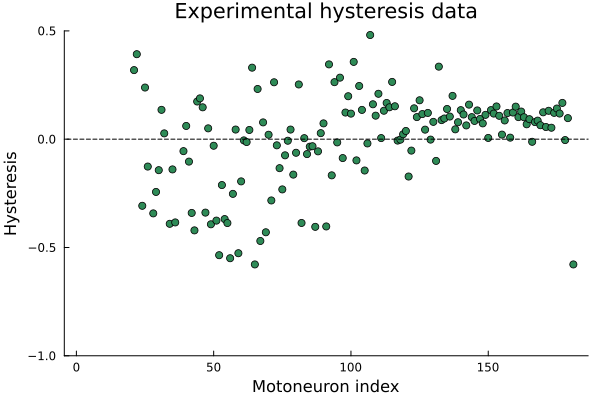

In [7]:
# Plot experimental hysteresis distribution
Plots.scatter(1:length(hysteresis_exp), hysteresis_exp,xlabel="Motoneuron index", ylabel="Hysteresis",
    title="Experimental hysteresis data",ylim=(-1, 0.5), legend=false,markersize=4, markercolor=:seagreen,grid=false)
Plots.hline!([0], linestyle=:dash, color=:black, linewidth=1)

---

## 3. Initialize model parameters

### 3.1 Configure motoneuron pool

In [8]:
# Number of motoneurons (match experimental data)
nr_s = length(hysteresis_exp)

println("Model configuration:")
println("  Number of motoneurons: ", nr_s)

Model configuration:
  Number of motoneurons: 181


### 3.2 Morphological parameters

In [9]:
# Rheobase (no noise for optimization)
rheobase_S = LinRange(3.5, 6.5, nr_s)

# Soma dimensions (converted to cm)
rs_S = LinRange(38.75, 41.25, nr_s) ./ 10000
ls_S = LinRange(77.5, 82.5, nr_s) ./ 10000
rms_S = LinRange(1.15, 1.05, nr_s) .* 1000

# Dendrite dimensions (converted to cm)
rd_S = LinRange(20.75, 31.25, nr_s) ./ 10000
ld_S = LinRange(5500.0, 6800.0, nr_s) ./ 10000
rmd_S = LinRange(14.4, 10.70, nr_s) .* 1000

println("✓ Morphological parameters defined")

✓ Morphological parameters defined


### 3.3 Ion channel conductances

In [10]:
# Maximum conductances (mS/cm²)
max_gna = 30.0
max_gkf_S = ones(nr_s) .* 4.0
max_gks_S = LinRange(16, 25, nr_s)
max_gca_S = LinRange(0.038, 0.029, nr_s)

println("✓ Ion channel conductances defined")

✓ Ion channel conductances defined


### 3.4 Gating kinetics

In [11]:
# Rate constants (ms⁻¹)
αm = ones(nr_s) .* 22.0
βm = ones(nr_s) .* 13.0
αh_S = ones(nr_s) .* 0.5
βh_S = ones(nr_s) .* 4.0
αn_S = ones(nr_s) .* 1.5
βn_S = ones(nr_s) .* 0.1
αq_S = ones(nr_s) .* 1.5
βq_S = LinRange(0.025, 0.038, nr_s)
αp_D = 0.008
βp_D = LinRange(0.014, 0.016, nr_s)

println("✓ Gating kinetics defined")

✓ Gating kinetics defined


### 3.5 Force parameters

In [12]:
# Twitch properties
Apeak_S = LinRange(0.103, 0.123, nr_s)
tpeak_S = LinRange(110.0, 100.0, nr_s)
tetanic_S = LinRange(0.393, 0.491, nr_s)

println("✓ Force parameters defined")

✓ Force parameters defined


### 3.6 Excitatory input profile

In [13]:
# Triangular ramp profile
amplitude = 0.4
tr_length = 28000
sim_length = 30000

half_triang = div(tr_length, 2)
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length=half_triang + 1)
down = range(amplitude, -0.1, length=tr_length - half_triang + 1)
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)

println("✓ Excitatory input profile created")
println("  Duration: ", sim_length, " ms")
println("  Amplitude: ", amplitude)

✓ Excitatory input profile created
  Duration: 30000 ms
  Amplitude: 0.4


### 3.7 System parameters

In [14]:
# Neuromodulation and inhibition
γa = 1.0
γh = ones(nr_s) .* 1.0
IF = LinRange(1.0, 1.0, nr_s)

# Reversal potentials (mV, centered at 0)
EL = 0; ENa = 120; ECa = 140; EK = -10; Ee = 70; Ei = -16

# Synaptic conductances
Ge = 0.6; Gi = 0.5

# Initial conditions
Vd0 = 0.0; Vs0 = 0.0

# Spike parameters
rp = 5.0  # Refractory period (ms)
pd = 1.0  # Pulse duration (ms)

# Time step
const step = 0.05
_int(num) = floor(Int, num)

# Physical constants
ri = 70.0  # Intracellular resistivity (Ω⋅cm)
cm = 1.0   # Membrane capacitance (μF/cm²)

# Initialize VthCa (will be optimized)
Vthca_S = zeros(nr_s)

println("✓ System parameters defined")

✓ System parameters defined


### 3.8 Compute derived properties

In [15]:
# Preallocate arrays
MN_list = []
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s)
gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s)
gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s)
cs_S = zeros(nr_s); cd_S = zeros(nr_s)

# Compute for each motoneuron
for i in 1:nr_s
    # Conductances and capacitances
    gls_S[i] = ((2π * rs_S[i] * ls_S[i]) / rms_S[i]) * 1e6
    gld_S[i] = ((2π * rd_S[i] * ld_S[i]) / rmd_S[i]) * 1e6
    gc_S[i] = (2 / ((ri * ld_S[i] / (π * rd_S[i]^2)) + 
                    (ri * ls_S[i] / (π * rs_S[i]^2)))) * 1e6
    rn_S[i] = 1 / (gls_S[i] + ((gld_S[i] * gc_S[i]) / (gld_S[i] + gc_S[i])))
    Vth_S[i] = round(rn_S[i] * rheobase_S[i], digits=2)
    cs_S[i] = 2π * ls_S[i] * rs_S[i] * cm * 1e3
    cd_S[i] = 2π * ld_S[i] * rd_S[i] * cm * 1e3
    
    # Ionic conductances
    gna_S[i] = 2π * ls_S[i] * rs_S[i] * max_gna * 1e3
    gkf_S[i] = 2π * ls_S[i] * rs_S[i] * max_gkf_S[i] * 1e3
    gks_S[i] = 2π * ls_S[i] * rs_S[i] * max_gks_S[i] * 1e3
    gca_S[i] = 2π * ld_S[i] * rd_S[i] * max_gca_S[i] * 1e3
    
    # Create parameter dictionary
    S_MN = Dict(
        :Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i],
        :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i],
        :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i],
        :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i],
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i],
        :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i],
        :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i],
        :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],
        :IF => IF[i], :tpeak => tpeak_S[i], :γh => γh[i],
        "type" => "All Type"
    )
    
    push!(MN_list, S_MN)
end

MNs = MN_list

println("✓ Computed properties for ", nr_s, " motoneurons")

✓ Computed properties for 181 motoneurons


### 3.9 Initialize simulation arrays

In [16]:
# Time span
tspan = 0:0.05:sim_length
sim_time = _int(sim_length / 0.05)

# Initial conditions
m = 0.0; h = 1.0; n = 0.0; q = 0.0; p = 0.0
m0 = 0.0; h0 = 1.0; n0 = 0.0; q0 = 0.0; p0 = 0.0
t0 = -1.0; t1 = -1.0; SPIKE0 = 0; SPIKE1 = 0

pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s)

# Storage arrays
spike_arr = zeros(nr_s, sim_time)
vs_arr = zeros(nr_s, sim_time)
pt_arr = zeros(nr_s, sim_time)
mt_arr = zeros(nr_s, sim_time)
ht_arr = zeros(nr_s, sim_time)
nt_arr = zeros(nr_s, sim_time)
qt_arr = zeros(nr_s, sim_time)

# Input arrays
commoninput = tr
full_input = zeros(nr_s, sim_length)
independantnoise = zeros(nr_s, sim_length)

# Inhibitory input
factor = 0.1
inh_input = fill(factor * amplitude, sim_length)

println("✓ Simulation arrays initialized")

✓ Simulation arrays initialized


---

## 4. Run optimization

### 4.1 Configure optimization parameters

In [18]:
# Optimization settings
convergence_threshold = 0.005  # Target error threshold
max_iterations_per_neuron = 5  # Maximum retry attempts
max_time_seconds = 200.0       # Time per optimization attempt
vthca_search_range = (0.0, 7.0)  # Search range for VthCa

println("Optimization configuration:")
println("  Convergence threshold: ", convergence_threshold)
println("  Max iterations per neuron: ", max_iterations_per_neuron)
println("  Max time per attempt: ", max_time_seconds, " seconds")
println("  VthCa search range: ", vthca_search_range)


Optimization configuration:
  Convergence threshold: 0.005
  Max iterations per neuron: 5
  Max time per attempt: 200.0 seconds
  VthCa search range: (0.0, 7.0)


### 4.2 Execute optimization loop

In [ ]:
println("\n" * "="^70)
println("STARTING OPTIMIZATION")
println("="^70)
println()

# Initialize tracking variables
global fitness_history = Float64[]
global smoothed_fitness_values = []

# Storage for results
results = Dict()

# Track overall progress
neurons_to_optimize = count(hysteresis_exp .< 0)
neurons_completed = 0

println("Total neurons to optimize: ", neurons_to_optimize, " / ", nr_s)
println()

# Optimize each neuron
for i in 1:nr_s
    println("─"^70)
    println("Neuron ", i, " / ", nr_s)
    println("─"^70)
    
    # Only optimize neurons with negative hysteresis (PICs present)
    if hysteresis_exp[i] < 0
        println("Target hysteresis: ", round(hysteresis_exp[i], digits=4))
        
        # Reset for this neuron
        fitness_history = []
        best_fitness_val = Inf
        iteration = 0
        
        # Iterative optimization with increasing complexity
        while best_fitness_val >= convergence_threshold
            iteration += 1
            println("\n  Attempt ", iteration, " / ", max_iterations_per_neuron)
            
            # Adaptive parameters (increase with iterations)
            pop_size = 100 + 10 * iteration
            mutation_rate = min(0.8 + 0.05 * iteration, 0.95)
            crossover_rate = min(0.8 + 0.05 * iteration, 0.95)
            
            println("    Population size: ", pop_size)
            println("    Mutation rate: ", round(mutation_rate, digits=2))
            println("    Crossover rate: ", round(crossover_rate, digits=2))
            
            # Run black-box optimization
            result = bboptimize(
                x -> wrap_objective(x, i, Vthca_S, MN_list, hysteresis_exp);
                SearchRange = [vthca_search_range],
                Method = :adaptive_de_rand_1_bin_radiuslimited,
                MaxTime = max_time_seconds,
                PopulationSize = pop_size,
                MutationRate = mutation_rate,
                CrossoverRate = crossover_rate
            )
            
            # Extract results
            best_params = best_candidate(result)
            best_fitness_val = best_fitness(result)
            
            println("    Optimized VthCa: ", round(best_params[1], digits=4))
            println("    Error: ", round(best_fitness_val, digits=6))
            
            # Check convergence
            if best_fitness_val < convergence_threshold
                println("    ✓ CONVERGED (error < ", convergence_threshold, ")")
                results[i] = (minimizer=best_params, minimum=best_fitness_val)
                break
            elseif iteration >= max_iterations_per_neuron
                println("    ⚠️  Maximum iterations reached")
                println("    → Using best result (error = ", round(best_fitness_val, digits=6), ")")
                results[i] = (minimizer=best_params, minimum=best_fitness_val)
                break
            else
                println("    → Retrying with increased complexity...")
            end
        end
        
        neurons_completed += 1
        println("\n  Progress: ", neurons_completed, " / ", neurons_to_optimize, " neurons optimized")
        
    else
        # No PIC - skip optimization
        println("No PIC detected (hysteresis = ", round(hysteresis_exp[i], digits=4), ")")
        println("→ Skipping optimization")
        results[i] = 0
    end
    
    println()
end

println("="^70)
println("OPTIMIZATION COMPLETED")
println("="^70)
println("\n✓ All neurons processed!")


STARTING OPTIMIZATION

Total neurons to optimize: 59 / 181

──────────────────────────────────────────────────────────────────────
Neuron 1 / 181
──────────────────────────────────────────────────────────────────────
No PIC detected (hysteresis = 2.2906)
→ Skipping optimization

──────────────────────────────────────────────────────────────────────
Neuron 2 / 181
──────────────────────────────────────────────────────────────────────
No PIC detected (hysteresis = 2.0839)
→ Skipping optimization

──────────────────────────────────────────────────────────────────────
Neuron 3 / 181
──────────────────────────────────────────────────────────────────────
No PIC detected (hysteresis = 1.8445)
→ Skipping optimization

──────────────────────────────────────────────────────────────────────
Neuron 4 / 181
──────────────────────────────────────────────────────────────────────
No PIC detected (hysteresis = 2.7669)
→ Skipping optimization

───────────────────────────────────────────────────────────

┌ Warning: Optimization interrupted, recovering intermediate results...
└ @ BlackBoxOptim ~/.julia/packages/BlackBoxOptim/lZtsr/src/opt_controller.jl:483


0.00 secs, 0 evals, 0 steps


---

## 5. Extract and analyze results

### 5.1 Extract optimized VthCa values

In [1]:
# Extract VthCa values for TA muscle
VthCa_newTA = zeros(1, nr_s)

for i in 1:nr_s
    if hysteresis_exp[i] < 0
        VthCa_newTA[i] = results[i].minimizer[1]
    else
        VthCa_newTA[i] = 0.0  # No PIC
    end
end

println("✓ VthCa values extracted")
println("  Neurons with PICs: ", count(VthCa_newTA .> 0))
println("  Mean VthCa (PIC neurons): ", round(mean(VthCa_newTA[VthCa_newTA .> 0]), digits=3))
println("  Range: [", round(minimum(VthCa_newTA[VthCa_newTA .> 0]), digits=3), ", ",round(maximum(VthCa_newTA[VthCa_newTA .> 0]), digits=3), "]")

LoadError: UndefVarError: nr_s not defined

### 5.2 Extract optimization errors

In [ ]:
# Extract error values
neuron_indices = Int[]
minimum_values = Float64[]

for (key, value) in results
    push!(neuron_indices, key)
    if isa(value, NamedTuple) && haskey(value, :minimum)
        push!(minimum_values, value.minimum)
    else
        push!(minimum_values, NaN)  # Neuron not optimized
    end
end

# Sort by neuron index
sorted_indices = sortperm(neuron_indices)
sorted_neuron_indices = neuron_indices[sorted_indices]
sorted_minimum_values = minimum_values[sorted_indices]

# Calculate statistics (excluding NaN)
valid_errors = sorted_minimum_values[.!isnan.(sorted_minimum_values)]

println("\nOptimization error statistics:")
println("  Mean error: ", round(mean(valid_errors), digits=6))
println("  Std dev: ", round(std(valid_errors), digits=6))
println("  Max error: ", round(maximum(valid_errors), digits=6))
println("  Neurons below threshold: ", count(valid_errors .< convergence_threshold), " / ", length(valid_errors))

---

## 6. Visualization

### 6.1 Optimization error per neuron

In [ ]:
# Plot optimization errors
Plots.plot(sorted_neuron_indices, sorted_minimum_values,xlabel="Motoneuron index", ylabel="Optimization error",
    title="Optimization accuracy (TA muscle)",markershape=:circle, markercolor=:blue,line=:solid, linewidth=2,grid=false, legend=false,ylim=(-0.1, 0.5))

# Add convergence threshold line
Plots.hline!([convergence_threshold], linestyle=:dash, color=:red, 
       linewidth=2, label="Convergence threshold")


# Uncomment to save:
# savefig("/Users/nmt121/Desktop/figures/error_TA_subject1.pdf")

### 6.2 VthCa distribution across pool

In [ ]:
# Plot VthCa distribution
Plots.plot(1:nr_s, VthCa_newTA[1, :],xlabel="Motoneuron index", ylabel="VthCa (mV)",title="Optimized calcium threshold distribution (TA)",markershape=:circle, markercolor=:blue,line=:solid, linewidth=2,grid=false, legend=false)

# Uncomment to save:
# savefig("/Users/nmt121/Desktop/figures/VthCa_TA_subject1.pdf")

---

## 7. Save results

### 7.1 Configure output paths

In [ ]:
# Define output directory
output_dir = "Data_MN_Model/Data_final/Subjects_optim_process"

# Create directory if needed
if !isdir(output_dir)
    mkpath(output_dir)
    println("Created output directory: ", output_dir)
end

# Define subject and muscle identifiers (MODIFY AS NEEDED)
subject_id = "subject1"
muscle_type = "TA"  # TA or VL
gamma_value = "gamma1"

println("\nOutput configuration:")
println("  Subject: ", subject_id)
println("  Muscle: ", muscle_type)
println("  Gamma: ", gamma_value)
println("  Directory: ", output_dir)

### 7.2 Save optimized parameters

In [ ]:
# Construct filenames
vthca_filename = "VthCa_$(muscle_type)_$(subject_id)_$(gamma_value).jld2"
error_filename = "accuracy_optim_$(muscle_type)_$(subject_id)_$(gamma_value).jld2"
indices_filename = "indices_optim_$(muscle_type)_$(subject_id)_$(gamma_value).jld2"

# Save VthCa values
JLD2.@save joinpath(output_dir, vthca_filename) VthCa_newTA
println("✓ Saved: ", vthca_filename)

# Save optimization errors
JLD2.@save joinpath(output_dir, error_filename) sorted_minimum_values
println("✓ Saved: ", error_filename)

# Save neuron indices
JLD2.@save joinpath(output_dir, indices_filename) sorted_neuron_indices
println("✓ Saved: ", indices_filename)

println("\n✓ All results saved to: ", output_dir)